<div style="padding: 10px 0 4px 0;">
  <img src="assets/q_learning_cover.png" alt="Q-Learning 在 FrozenLake 中学习最优路线的原创插图" style="width:100%; border-radius:16px; display:block;">
</div>

# 从零手撕 Q-Learning：一张 Q-table 如何学会走出冰湖

> **目标**：不把 Q-Learning 当成一段需要背诵的代码，而是亲眼看到一张全零表格如何通过“试错—更新—再试错”，逐渐变成可执行的策略。

本章使用 Gymnasium 的 `FrozenLake-v1`。我们先关闭冰面打滑，让因果关系足够清楚；最后再打开随机性，观察同一算法在不确定环境中的变化。

**学完你将能够：**

1. 用“状态 × 动作”解释 Q-table 的行、列和数值；
2. 逐项读懂 Q-Learning 更新公式；
3. 自己实现 $\varepsilon$-greedy、TD target 和 Q-table 更新；
4. 从训练曲线、Q 值热力图和策略路径判断是否真的学会；
5. 说清楚 Q-table 的能力边界，以及为什么大状态空间需要神经网络。

<small>封面为本项目原创生成素材；正文中的图表均由代码实时绘制。</small>


## 0. 学习路线图

这份 notebook 按照从直觉到实现、再到验证与扩展的顺序组织。建议依次完成下面 6 个阶段：

| 阶段 | 核心问题 | 关键结论 |
|---|---|---|
| 1. 环境 | 智能体面对什么？ | 强化学习是连续的交互过程 |
| 2. 表格 | Q-table 在存什么？ | 每个格子是“在某状态做某动作”的长期价值 |
| 3. 更新 | 一次经验怎样写进表格？ | 新估计向 TD target 靠近 |
| 4. 探索 | 全零开局怎么学？ | $\varepsilon$-greedy 在探索与利用间取舍 |
| 5. 训练 | 怎样判断学会了？ | 曲线、策略与独立评估缺一不可 |
| 6. 边界 | Q-table 为什么不适合所有任务？ | 表格随状态维度指数膨胀 |

> **学习建议**：运行每个代码单元前，先预测输出；运行后再解释结果是否符合预期。主动预测比逐行阅读代码更容易建立直觉。


## 1. 准备环境

推荐 Python 3.10+。第一次运行时，如缺少依赖，可取消下一格第一行的注释进行安装。


In [1]:
# %pip install "gymnasium==1.3.0" numpy pandas matplotlib

import platform

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyArrowPatch, Rectangle
from IPython.display import display

SEED = 42
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

print(f"Python    : {platform.python_version()}")
print(f"Gymnasium : {gym.__version__}")
print(f"NumPy     : {np.__version__}")


Python    : 3.10.21
Gymnasium : 1.3.0
NumPy     : 2.2.6


## 2. 先看任务：智能体要在冰湖上做什么？

FrozenLake 是一个 $4\times4$ 网格世界：

- `S`（Start）：起点；
- `F`（Frozen）：可安全停留的冰面；
- `H`（Hole）：冰洞，掉进去后本回合结束；
- `G`（Goal）：终点，到达后得到奖励 $1$。

除到达 `G` 外，其他转移的即时奖励都是 $0$。这叫做**稀疏奖励**：智能体必须先偶然成功，才能把有用信息逐步向起点传播。


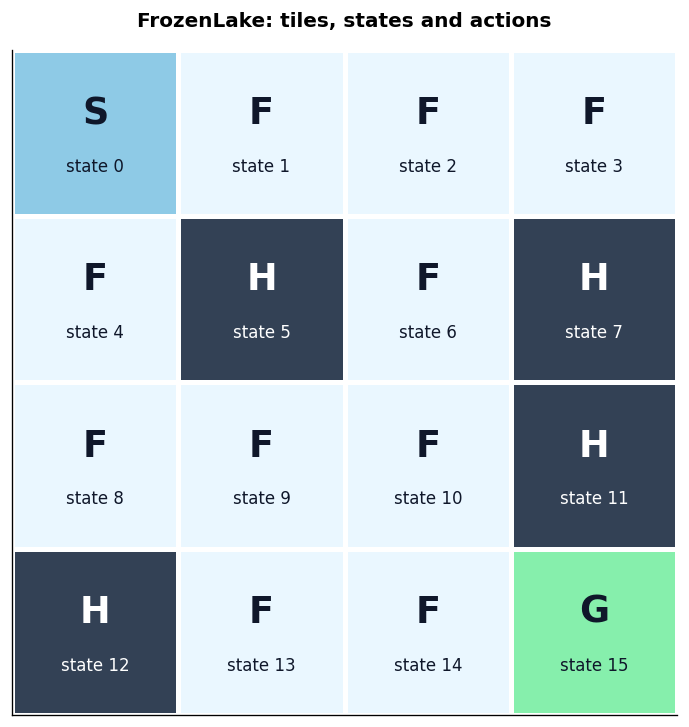

In [2]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=False)

ACTION_NAMES = np.array(["LEFT", "DOWN", "RIGHT", "UP"])
ACTION_SYMBOLS = np.array(["←", "↓", "→", "↑"])
TILE_COLORS = {"S": "#8ECAE6", "F": "#EAF7FF", "H": "#334155", "G": "#86EFAC"}


def decode_map(environment):
    """把 Gymnasium 内部的字节地图转为普通字符串矩阵。"""
    return np.array([
        [cell.decode("utf-8") for cell in row]
        for row in environment.unwrapped.desc
    ])


def plot_lake(environment, title="FrozenLake: tiles, states and actions"):
    lake = decode_map(environment)
    n_rows, n_cols = lake.shape
    fig, ax = plt.subplots(figsize=(7.2, 7.2))

    for row in range(n_rows):
        for col in range(n_cols):
            tile = lake[row, col]
            state = row * n_cols + col
            ax.add_patch(Rectangle(
                (col, row), 1, 1,
                facecolor=TILE_COLORS[tile], edgecolor="white", linewidth=3,
            ))
            text_color = "white" if tile == "H" else "#0F172A"
            ax.text(col + 0.5, row + 0.38, tile, ha="center", va="center",
                    fontsize=22, fontweight="bold", color=text_color)
            ax.text(col + 0.5, row + 0.70, f"state {state}", ha="center", va="center",
                    fontsize=10, color=text_color)

    ax.set(xlim=(0, n_cols), ylim=(n_rows, 0), aspect="equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, pad=14)
    plt.show()


plot_lake(env)


### 2.1 状态不是坐标，而是一个整数

Gymnasium 把位置 $(row, col)$ 压缩为：

$$
s = row \times n_{cols} + col
$$

因此左上角是状态 `0`，右下角是状态 `15`。反向换算可用 `divmod(state, n_cols)`。

动作同样用整数编码：`0=左`、`1=下`、`2=右`、`3=上`。**这些编号没有大小关系**；动作 `3` 并不比动作 `0` 更好。


In [3]:
n_states = env.observation_space.n
n_actions = env.action_space.n

state_action_overview = pd.DataFrame({
    "action id": np.arange(n_actions),
    "meaning": ACTION_NAMES,
    "symbol": ACTION_SYMBOLS,
})

print(f"状态数: {n_states} = 4 × 4")
print(f"动作数: {n_actions}")
display(state_action_overview)

example_state = 10
print(f"state {example_state} -> (row, col) = {divmod(example_state, 4)}")


状态数: 16 = 4 × 4
动作数: 4


,action id,meaning,symbol
0,0,LEFT,←
1,1,DOWN,↓
2,2,RIGHT,→
3,3,UP,↑


state 10 -> (row, col) = (2, 2)


### 2.2 一次交互到底返回什么？

Gymnasium 的一次交互分两步：

1. `state, info = env.reset()`：开启新回合并取得初始状态；
2. `next_state, reward, terminated, truncated, info = env.step(action)`：执行动作并接收反馈。

其中：

- `terminated=True`：自然到达终点或掉入冰洞；
- `truncated=True`：达到人为时间上限；
- 两者任一为真，本回合都应该停止。


In [4]:
state, info = env.reset(seed=SEED)
action = 2  # RIGHT
next_state, reward, terminated, truncated, info = env.step(action)

transition = pd.DataFrame([{
    "state": state,
    "action": f"{action} ({ACTION_NAMES[action]})",
    "reward": reward,
    "next_state": next_state,
    "terminated": terminated,
    "truncated": truncated,
}])
display(transition)


,state,action,reward,next_state,terminated,truncated
0,0,2 (RIGHT),0,1,False,False


## 3. Q-table 究竟是什么？

Q-table 是一张“**状态 × 动作**”的查找表：

| 当前状态 $s$ | $Q(s,\leftarrow)$ | $Q(s,\downarrow)$ | $Q(s,\rightarrow)$ | $Q(s,\uparrow)$ |
|---|---:|---:|---:|---:|
| 0 | ？ | ？ | ？ | ？ |
| 1 | ？ | ？ | ？ | ？ |
| $\vdots$ | $\vdots$ | $\vdots$ | $\vdots$ | $\vdots$ |
| 15 | ？ | ？ | ？ | ？ |

$Q(s,a)$ 不是“动作 $a$ 的即时奖励”，而是：

> 在状态 $s$ 选择动作 $a$，之后继续合理行动，**未来累计能获得多少奖励**的估计。

这一区分非常关键。FrozenLake 中绝大多数动作的即时奖励都是 0，但靠近终点的正确动作仍然很有价值，因为它们通向未来的奖励。


In [5]:
q_table = np.zeros((n_states, n_actions), dtype=float)


def q_dataframe(table):
    """把 Q-table 转成更适合人阅读的 DataFrame。"""
    return pd.DataFrame(
        table,
        index=[f"s={s:02d}" for s in range(table.shape[0])],
        columns=[f"{symbol} {name}" for symbol, name in zip(ACTION_SYMBOLS, ACTION_NAMES)],
    )


display(q_dataframe(q_table))
print("形状:", q_table.shape, "= 16 个状态 × 4 个动作")


,← LEFT,↓ DOWN,→ RIGHT,↑ UP
s=00,0.0,0.0,0.0,0.0
s=01,0.0,0.0,0.0,0.0
s=02,0.0,0.0,0.0,0.0
s=03,0.0,0.0,0.0,0.0
s=04,0.0,0.0,0.0,0.0
s=05,0.0,0.0,0.0,0.0
s=06,0.0,0.0,0.0,0.0
s=07,0.0,0.0,0.0,0.0
s=08,0.0,0.0,0.0,0.0
s=09,0.0,0.0,0.0,0.0


形状: (16, 4) = 16 个状态 × 4 个动作


### 为什么从全零开始？

开始时智能体没有经验，把所有 Q 值设为 0 表示“尚不知道哪个动作更好”。这不是说所有动作真的同样好，而是模型当前的估计相同。

全零还带来一个问题：如果永远只选最大值，`argmax` 会反复偏向第一个动作。因此训练时不能只有**利用**（exploitation），还要主动**探索**（exploration）。稍后我们会用 $\varepsilon$-greedy 解决。


## 4. 核心：一次经验怎样更新一个 Q 值？

Q-Learning 的更新公式是：

$$
Q(s,a) \leftarrow Q(s,a) + \alpha\Big[r + \gamma\max_{a'}Q(s',a') - Q(s,a)\Big]
$$

把长公式拆成 4 块：

| 记号 | 名称 | 直觉 |
|---|---|---|
| $Q(s,a)$ | 当前估计 | 更新前，我们认为这个动作值多少 |
| $r+\gamma\max_{a'}Q(s',a')$ | TD target | 眼前奖励 + 下一状态最好的未来 |
| $\delta=\text{target}-Q(s,a)$ | TD error | 新证据与旧判断相差多少 |
| $\alpha$ | 学习率 | 本次愿意吸收多少新证据 |

折扣因子 $\gamma\in[0,1]$ 决定“多重视未来”。$\gamma$ 越大，越愿意为远期奖励绕路。

> **终止状态特例**：若这一步已经结束回合，就没有“下一步的未来价值”，因此 target 只等于 $r$。


In [6]:
def update_q_value(old_q, reward, best_next_q, alpha, gamma, done=False):
    """返回 Q-Learning 一次更新的中间量，便于讲解。"""
    td_target = reward if done else reward + gamma * best_next_q
    td_error = td_target - old_q
    new_q = old_q + alpha * td_error
    return td_target, td_error, new_q


# 手算示例：旧估计 0.20，下一状态最好动作值 0.80，本步奖励为 0
example = dict(old_q=0.20, reward=0.0, best_next_q=0.80, alpha=0.50, gamma=0.90)
td_target, td_error, new_q = update_q_value(**example)

calculation = pd.DataFrame([{
    **example,
    "TD target": td_target,
    "TD error": td_error,
    "new Q": new_q,
}])
display(calculation.round(3))
print("解释: 新 Q = 0.20 + 0.50 × (0 + 0.90 × 0.80 - 0.20) =", round(new_q, 3))


,old_q,reward,best_next_q,alpha,gamma,TD target,TD error,new Q
0,0.2,0.0,0.8,0.5,0.9,0.72,0.52,0.46


解释: 新 Q = 0.20 + 0.50 × (0 + 0.90 × 0.80 - 0.20) = 0.46


上面的新 Q 值从 `0.20` 上升到 `0.46`。虽然这一步即时奖励是 0，但“下一状态很有前途”这一信息被折扣后传了回来。

这就是 Q-Learning 的核心机制：**奖励从终点开始，经过大量更新逐步向前传播。**

### 一个容易忽略的点：Q-Learning 是 off-policy

训练时，行为策略会用 $\varepsilon$-greedy 偶尔随机探索；但 target 中用的是 $\max_{a'}Q(s',a')$，也就是假设下一步选择当前认为最好的动作。因此“采样数据的策略”和“被学习的贪心策略”并不完全相同。


## 5. 探索与利用：$\varepsilon$-greedy

每一步抛一次“带偏置的硬币”：

- 以概率 $\varepsilon$：随机选动作，探索未知区域；
- 以概率 $1-\varepsilon$：选 Q 值最大的动作，利用已有知识。

训练初期应多探索，后期再逐步降低 $\varepsilon$。这里采用指数衰减：

$$
\varepsilon_t = \varepsilon_{min} + (\varepsilon_{max}-\varepsilon_{min})e^{-kt}
$$


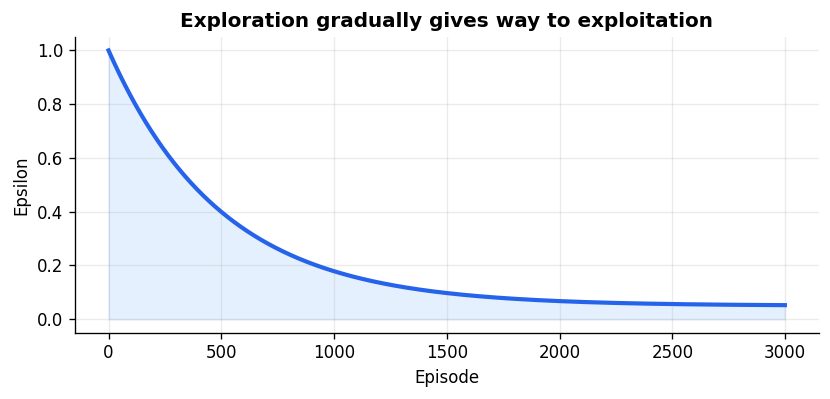

In [7]:
def epsilon_by_episode(episode, epsilon_start=1.0, epsilon_min=0.05, decay_rate=0.002):
    return epsilon_min + (epsilon_start - epsilon_min) * np.exp(-decay_rate * episode)


def choose_action(table, state, epsilon, rng):
    """以 epsilon 随机探索，否则在并列最优动作中随机选择一个。"""
    if rng.random() < epsilon:
        return int(rng.integers(table.shape[1]))

    values = table[state]
    best_actions = np.flatnonzero(np.isclose(values, values.max()))
    return int(rng.choice(best_actions))


episodes_axis = np.arange(3000)
epsilons = [epsilon_by_episode(ep) for ep in episodes_axis]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(episodes_axis, epsilons, color="#2563EB", linewidth=2.5)
ax.fill_between(episodes_axis, epsilons, alpha=0.16, color="#60A5FA")
ax.set(xlabel="Episode", ylabel="Epsilon", title="Exploration gradually gives way to exploitation")
ax.grid(alpha=0.25)
plt.show()


## 6. 把所有零件组装成训练循环

下面的函数刻意写得“可读而非炫技”。每个回合都经历：

```text
重置环境
    ↓
按 ε-greedy 选动作
    ↓
执行动作，得到 (s', r, done)
    ↓
计算 TD target 与 TD error
    ↓
只更新 Q[s, a]
    ↓
进入 s'，直到回合结束
```

我们同时记录奖励、步数、$\varepsilon$ 和平均 TD error，后面用它们诊断训练过程。


In [8]:
def train_q_learning(
    environment,
    episodes=5000,
    alpha=0.8,
    gamma=0.95,
    epsilon_start=1.0,
    epsilon_min=0.05,
    decay_rate=0.002,
    max_steps=100,
    seed=42,
):
    """在离散环境上训练 Q-table，并返回表格与诊断历史。"""
    rng = np.random.default_rng(seed)
    table = np.zeros((environment.observation_space.n, environment.action_space.n))
    history = {"reward": [], "steps": [], "epsilon": [], "mean_abs_td_error": []}

    for episode in range(episodes):
        state, _ = environment.reset(seed=seed + episode)
        epsilon = epsilon_min + (epsilon_start - epsilon_min) * np.exp(-decay_rate * episode)
        episode_reward = 0.0
        td_errors = []

        for step in range(1, max_steps + 1):
            action = choose_action(table, state, epsilon, rng)
            next_state, reward, terminated, truncated, _ = environment.step(action)
            done = terminated or truncated

            best_next_q = 0.0 if done else np.max(table[next_state])
            td_target = reward + gamma * best_next_q
            td_error = td_target - table[state, action]
            table[state, action] += alpha * td_error

            td_errors.append(abs(td_error))
            episode_reward += reward
            state = next_state

            if done:
                break

        history["reward"].append(episode_reward)
        history["steps"].append(step)
        history["epsilon"].append(epsilon)
        history["mean_abs_td_error"].append(np.mean(td_errors))

    return table, pd.DataFrame(history)


### 6.1 训练确定性冰湖

超参数不是魔法常数。这里的取值服务于教学演示：

- `alpha=0.8`：环境确定，允许较快吸收新经验；
- `gamma=0.95`：重视未来终点奖励；
- `epsilon: 1.0 → 0.05`：先广泛探索，再主要利用；
- `5000 episodes`：对这个小环境很充足，运行也很快。


In [9]:
q_table, history = train_q_learning(
    env,
    episodes=5000,
    alpha=0.8,
    gamma=0.95,
    epsilon_start=1.0,
    epsilon_min=0.05,
    decay_rate=0.002,
    seed=SEED,
)

print("训练完成。最后 500 回合成功率:", f"{history['reward'].tail(500).mean():.1%}")
display(q_dataframe(q_table).round(3))


训练完成。最后 500 回合成功率: 96.6%


,← LEFT,↓ DOWN,→ RIGHT,↑ UP
s=00,0.735,0.774,0.774,0.735
s=01,0.735,0.000,0.815,0.774
s=02,0.774,0.857,0.774,0.815
s=03,0.815,0.000,0.774,0.774
s=04,0.774,0.815,0.000,0.735
s=05,0.000,0.000,0.000,0.000
s=06,0.000,0.902,0.000,0.815
s=07,0.000,0.000,0.000,0.000
s=08,0.815,0.000,0.857,0.774
s=09,0.815,0.902,0.902,0.000


## 7. 不只看最终奖励：读懂训练曲线

单回合奖励只有 0 或 1，锯齿很正常。我们用 200 回合滑动平均观察趋势：

- 成功率上升：学到可达终点的策略；
- $\varepsilon$ 下降：随机探索在减少；
- TD error 整体下降：新经验与当前估计越来越一致。

注意：TD error 下降**不能单独证明策略好**。一个从未找到终点、整张表一直为零的智能体，TD error 也可能很小，所以必须结合成功率和独立评估。


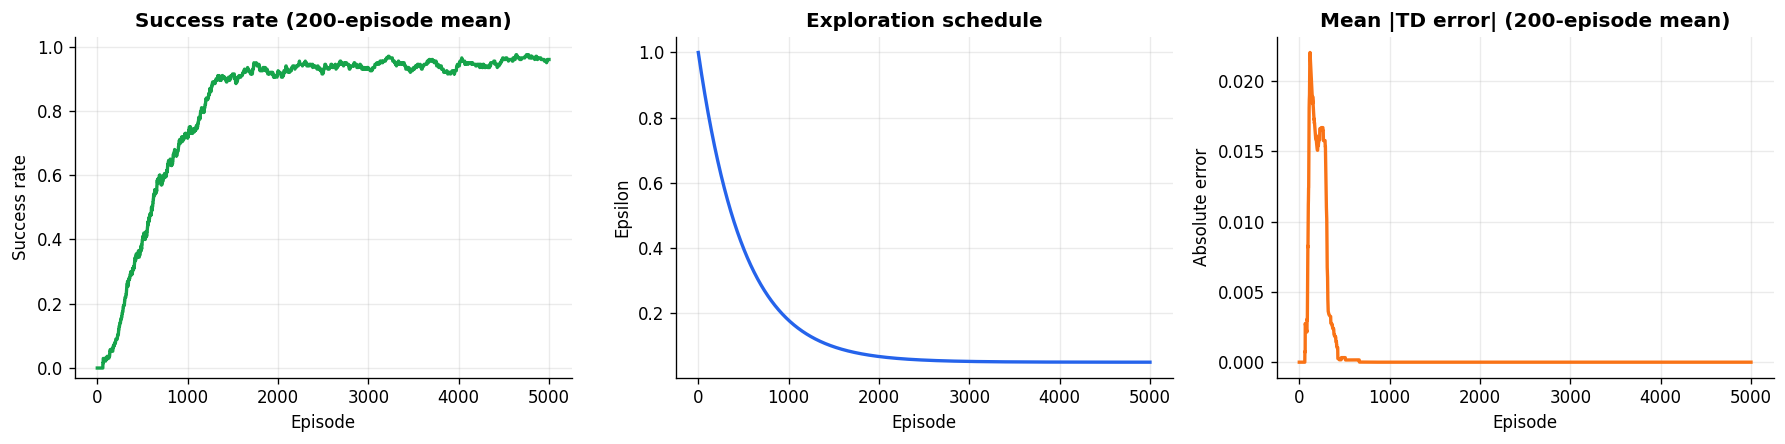

In [10]:
window = 200
rolling_success = history["reward"].rolling(window, min_periods=1).mean()
rolling_td = history["mean_abs_td_error"].rolling(window, min_periods=1).mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

axes[0].plot(rolling_success, color="#16A34A", linewidth=2)
axes[0].set(title=f"Success rate ({window}-episode mean)", xlabel="Episode", ylabel="Success rate", ylim=(-0.03, 1.03))

axes[1].plot(history["epsilon"], color="#2563EB", linewidth=2)
axes[1].set(title="Exploration schedule", xlabel="Episode", ylabel="Epsilon")

axes[2].plot(rolling_td, color="#F97316", linewidth=2)
axes[2].set(title=f"Mean |TD error| ({window}-episode mean)", xlabel="Episode", ylabel="Absolute error")

for ax in axes:
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 8. 把数字翻译成人能读懂的策略

对每个状态取 $\arg\max_a Q(s,a)$，就得到贪心策略：

$$
\pi(s)=\arg\max_a Q(s,a)
$$

下面左图把每个动作的 Q 值画成热力图；右图只保留每个状态的最佳动作。冰洞和终点是终止状态，其中的 Q 值不会影响决策。


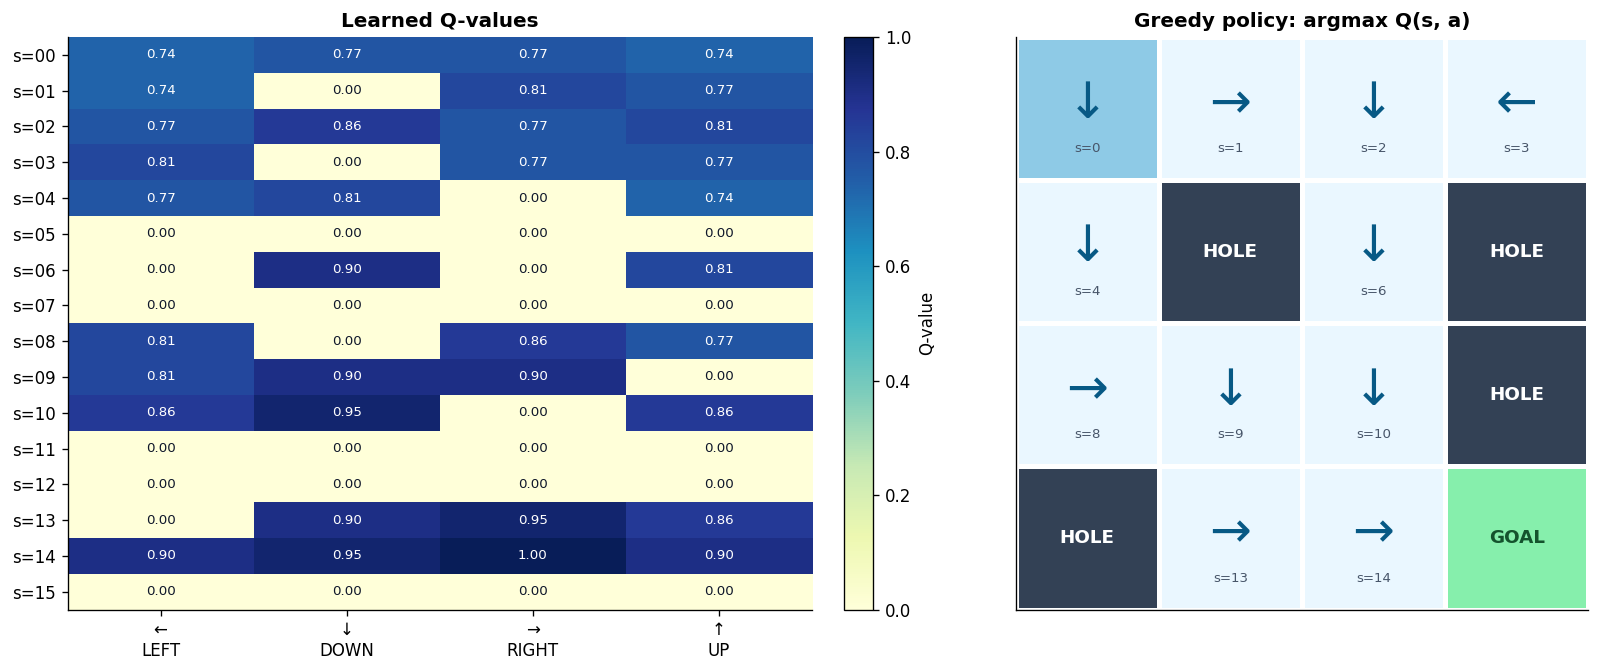

In [11]:
def plot_q_table_and_policy(table, environment):
    lake = decode_map(environment)
    n_rows, n_cols = lake.shape
    terminal_states = {
        r * n_cols + c
        for r in range(n_rows) for c in range(n_cols)
        if lake[r, c] in {"H", "G"}
    }

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.7), gridspec_kw={"width_ratios": [1.15, 1]})

    # 左：Q 值热力图
    im = axes[0].imshow(table, cmap="YlGnBu", aspect="auto")
    axes[0].set_xticks(range(4), [f"{s}\n{n}" for s, n in zip(ACTION_SYMBOLS, ACTION_NAMES)])
    axes[0].set_yticks(range(n_states), [f"s={s:02d}" for s in range(n_states)])
    axes[0].set_title("Learned Q-values")
    for s in range(table.shape[0]):
        for a in range(table.shape[1]):
            value = table[s, a]
            axes[0].text(a, s, f"{value:.2f}", ha="center", va="center",
                         fontsize=8, color="white" if value > table.max() * 0.55 else "#0F172A")
    fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04, label="Q-value")

    # 右：策略网格
    ax = axes[1]
    for row in range(n_rows):
        for col in range(n_cols):
            state = row * n_cols + col
            tile = lake[row, col]
            ax.add_patch(Rectangle((col, row), 1, 1, facecolor=TILE_COLORS[tile],
                                   edgecolor="white", linewidth=3))
            if state in terminal_states:
                label = "HOLE" if tile == "H" else "GOAL"
                color = "white" if tile == "H" else "#14532D"
                ax.text(col + 0.5, row + 0.5, label, ha="center", va="center",
                        fontweight="bold", fontsize=11, color=color)
            else:
                best_action = int(np.argmax(table[state]))
                ax.text(col + 0.5, row + 0.47, ACTION_SYMBOLS[best_action],
                        ha="center", va="center", fontsize=30, color="#075985")
                ax.text(col + 0.5, row + 0.78, f"s={state}", ha="center", va="center",
                        fontsize=8, color="#475569")
    ax.set(xlim=(0, n_cols), ylim=(n_rows, 0), aspect="equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title("Greedy policy: argmax Q(s, a)")

    plt.tight_layout()
    plt.show()


plot_q_table_and_policy(q_table, env)


### 8.1 为什么最优策略可能不唯一？

在确定性 $4\times4$ 地图里，若两条安全路线长度相同，它们的理论回报可以相同。训练得到哪一条，取决于探索过程和并列时的选择方式。

因此不要把“箭头与某张标准答案图完全一致”当成唯一验收条件。真正重要的是：路径安全、能到终点、回报稳定。


## 9. 独立评估：关闭探索后，它真的会走吗？

评估阶段设置 $\varepsilon=0$，只执行学到的贪心策略。训练数据和评估数据要分开，否则我们看到的可能只是探索噪声。


In [12]:
def evaluate_greedy_policy(environment, table, episodes=200, max_steps=100, seed=10_000):
    rewards, lengths, trajectories = [], [], []

    for episode in range(episodes):
        state, _ = environment.reset(seed=seed + episode)
        trajectory = [state]
        total_reward = 0.0

        for step in range(1, max_steps + 1):
            action = int(np.argmax(table[state]))
            state, reward, terminated, truncated, _ = environment.step(action)
            trajectory.append(state)
            total_reward += reward
            if terminated or truncated:
                break

        rewards.append(total_reward)
        lengths.append(step)
        trajectories.append(trajectory)

    return {
        "success_rate": float(np.mean(rewards)),
        "mean_steps": float(np.mean(lengths)),
        "trajectories": trajectories,
    }


evaluation = evaluate_greedy_policy(env, q_table)
print(f"Greedy success rate : {evaluation['success_rate']:.1%}")
print(f"Average steps       : {evaluation['mean_steps']:.2f}")
print("One trajectory      :", " → ".join(map(str, evaluation["trajectories"][0])))


Greedy success rate : 100.0%
Average steps       : 6.00
One trajectory      : 0 → 4 → 8 → 9 → 13 → 14 → 15


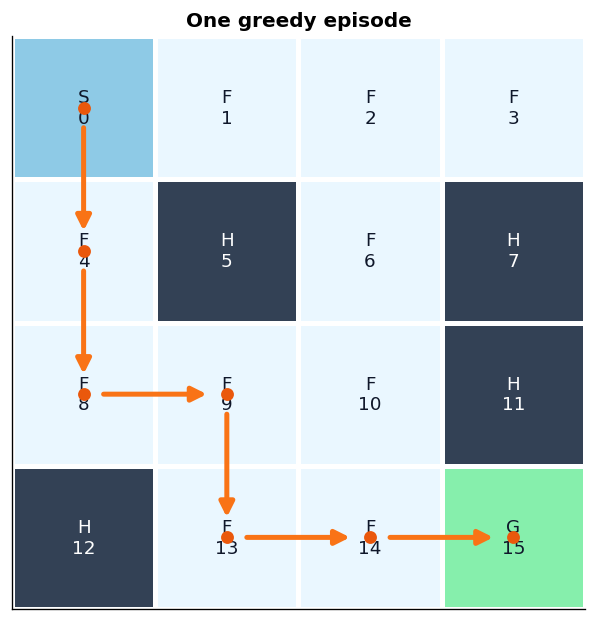

In [13]:
def plot_trajectory(environment, trajectory, title="One greedy episode"):
    lake = decode_map(environment)
    n_rows, n_cols = lake.shape
    fig, ax = plt.subplots(figsize=(6.2, 6.2))

    for row in range(n_rows):
        for col in range(n_cols):
            tile = lake[row, col]
            ax.add_patch(Rectangle((col, row), 1, 1, facecolor=TILE_COLORS[tile],
                                   edgecolor="white", linewidth=3))
            ax.text(col + 0.5, row + 0.5, f"{tile}\n{row*n_cols+col}",
                    ha="center", va="center", fontsize=11,
                    color="white" if tile == "H" else "#0F172A")

    points = [(s % n_cols + 0.5, s // n_cols + 0.5) for s in trajectory]
    for start, end in zip(points[:-1], points[1:]):
        ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=18,
                                    linewidth=3, color="#F97316", shrinkA=12, shrinkB=12))
    ax.scatter(*zip(*points), s=45, color="#EA580C", zorder=5)
    ax.set(xlim=(0, n_cols), ylim=(n_rows, 0), aspect="equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title)
    plt.show()


plot_trajectory(env, evaluation["trajectories"][0])


## 10. 从终点倒推：奖励如何“传”回起点？

观察最终 Q-table 时，通常会看到离终点越近、且能安全通向终点的动作，Q 值越高。若每一步奖励都是 0，成功路径上距离终点 $d$ 步的理想价值大致按 $\gamma^{d-1}$ 衰减。

例如最后一步进入终点时 target 为 $1$；前一个状态随后能学到约 $\gamma$；再前一个状态约为 $\gamma^2$。这也是“长期价值”与“即时奖励”的区别。


In [14]:
trajectory = evaluation["trajectories"][0]
rows = []
for state, next_state in zip(trajectory[:-1], trajectory[1:]):
    action = int(np.argmax(q_table[state]))
    rows.append({
        "state": state,
        "greedy action": f"{ACTION_SYMBOLS[action]} {ACTION_NAMES[action]}",
        "Q(s,a)": q_table[state, action],
        "next state": next_state,
    })

display(pd.DataFrame(rows).round(3))


,state,greedy action,"Q(s,a)",next state
0,0,↓ DOWN,0.774,4
1,4,↓ DOWN,0.815,8
2,8,→ RIGHT,0.857,9
3,9,↓ DOWN,0.902,13
4,13,→ RIGHT,0.950,14
5,14,→ RIGHT,1.000,15


## 11. 进阶实验：重新打开“打滑”

`is_slippery=True` 时，选定动作并不保证按计划移动。同一个 $(s,a)$ 可能到达不同 $s'$，环境变成随机的。

此时 Q 值表达的是**期望回报**，而不再是某条固定路线的确定结果。训练通常需要：

- 更多回合来平均随机性；
- 更小的学习率，减少单次偶然转移的冲击；
- 保留一定探索率。

下面是可选实验，运行时间仍然很短。


In [15]:
slippery_env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True)

slippery_q, slippery_history = train_q_learning(
    slippery_env,
    episodes=20_000,
    alpha=0.10,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_min=0.05,
    decay_rate=0.0003,
    seed=SEED,
)

slippery_eval = evaluate_greedy_policy(
    slippery_env, slippery_q, episodes=1000, seed=20_000
)

comparison = pd.DataFrame([
    {"environment": "Deterministic", "success rate": evaluation["success_rate"], "mean steps": evaluation["mean_steps"]},
    {"environment": "Slippery", "success rate": slippery_eval["success_rate"], "mean steps": slippery_eval["mean_steps"]},
])
comparison_display = comparison.copy()
comparison_display["success rate"] = comparison_display["success rate"].map("{:.1%}".format)
comparison_display["mean steps"] = comparison_display["mean steps"].map("{:.2f}".format)
display(comparison_display)


,environment,success rate,mean steps
0,Deterministic,100.0%,6.00
1,Slippery,74.5%,44.05


随机环境的成功率通常低于 100%，这并不自动意味着没学会。关键是与随机策略、不同超参数和多次随机种子的结果比较。

> **严谨实验提醒**：教学演示固定一个 seed 是为了可复现；正式报告算法性能时，应使用多个 seed，报告均值与波动，而不是只展示最好的一次。


## 12. 常见错误与排查清单

| 症状 | 常见原因 | 修复方式 |
|---|---|---|
| Q-table 始终全零 | 从未到达终点，奖励没有出现 | 增加探索、回合数；确认环境奖励 |
| 智能体总选 LEFT | 全零并列时 `argmax` 固定返回索引 0 | 训练时使用随机探索，并随机打破并列 |
| 终点附近 Q 值异常 | 终止后仍加入下一状态价值 | `done=True` 时 bootstrap 项设为 0 |
| 训练成功、评估很差 | 评估仍在随机探索，或混用了表格 | 评估设 $\varepsilon=0$，单独封装函数 |
| 每次结果差异很大 | 没有控制随机种子，或环境本身随机 | 固定 seed；正式实验运行多个 seed |
| 曲线偶尔下降 | 探索仍在继续，这是正常波动 | 看滑动平均，不要只看单回合 |

### 参数的方向感

- $\alpha$ 太大：学习快但容易受噪声影响；太小：稳定但收敛慢。
- $\gamma$ 太小：只顾眼前；太大：更重视长期回报。
- $\varepsilon$ 降得太快：可能过早锁定差策略；降得太慢：后期仍频繁乱走。

三者相互影响。调参前先确认更新公式、终止处理和评估流程正确。


## 13. Q-table 的边界：什么时候该换成 DQN？

Q-table 的大小是：

$$
|\mathcal{S}|\times|\mathcal{A}|
$$

FrozenLake 只有 $16\times4=64$ 个格子，非常适合表格法。但如果输入是一张 $84\times84$ 的灰度图，仅可能像素组合就接近 $256^{7056}$，根本无法逐项建表。

这时可用神经网络近似 $Q(s,a)$，得到 DQN。**变化的是表示方式，不变的是核心目标**：仍然希望估计“在状态 $s$ 做动作 $a$ 的长期价值”。

| 方法 | Q 值怎样存 | 适合场景 |
|---|---|---|
| Q-table | 数组中精确存每个 $(s,a)$ | 状态、动作离散且规模小 |
| DQN | 神经网络从状态预测各动作 Q 值 | 高维状态、无法穷举 |


## 14. 课后练习（从复现到真正理解）

1. **奖励塑形**：每走一步给 `-0.01`，观察路线长度是否变化。思考：这是否改变了原任务？
2. **参数消融**：只改变 $\gamma\in\{0,0.5,0.95,0.999\}$，比较 Q-table 和成功率。
3. **探索策略**：把 $\varepsilon$ 固定为 `0`、`0.1`、`1.0`，解释三种失败方式。
4. **更大地图**：改成 `map_name="8x8"`，估计需要多少训练回合。
5. **多随机种子**：运行 10 个 seed，报告平均成功率和标准差。
6. **实现 SARSA**：把 target 的 $\max Q(s',a')$ 改为实际选出的 $Q(s',a')$，比较 on-policy 与 off-policy。

### 一句话总结

> Q-Learning 用一次次转移产生的 TD error，修正 Q-table 中一个状态—动作格子；在探索积累的数据中，终点奖励逐渐向前传播，最终 `argmax Q(s, a)` 就成为可执行的策略。


---

## 15. 学习笔记的复现与维护

- 将本 notebook 与 `assets/q_learning_cover.png` 放在同一项目结构中，确保离线也能完整显示；
- 使用 `requirements.txt` 或 `environment.yml` 固定依赖版本；
- 修改代码后执行一次 **Restart Kernel and Run All Cells**，确认从空内核按顺序运行无隐藏状态；
- 记录随机种子与超参数，避免把偶然结果误当成稳定结论；
- 扩展实验时一次只改变一个变量，并保留对照结果。

完成这些步骤后，这份笔记就能作为后续 SARSA、DQN 等算法学习的可靠基线。
